# Evaluasi Pipeline Moderasi Chat

```
chat mentah -> T1 normalisasi -> T2 klasifikasi -> T3 tagging kata -> chat tersensor
```

Pipeline menghasilkan dua keputusan yang dilihat pemain:

1. **Warning**, per baris chat: T2 memutuskan apakah baris toksik. Keputusan ini juga menentukan apakah T3 dijalankan (gate).
2. **Sensor**, per kata: T3 memutuskan kata mana yang diganti `*`, hanya di baris yang diberi warning.

T1 tidak menghasilkan keputusan yang dilihat pemain. Kualitas normalisasinya dinilai di notebook Task 1. Di sini yang diukur adalah pengaruh T1 terhadap dua keputusan di atas.

Bagian 1 berisi rancangan evaluasi. Bagian 2 sampai 8 berisi hasil. Bagian 9 dan 10 berisi kesimpulan dan keterbatasan.

## Setup

In [1]:
# Imports and Paths
import json
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo = Path.cwd()
while not (repo / "pyproject.toml").exists():
    repo = repo.parent
PIPELINE_DIR = repo / "src" / "pipeline"
sys.path[:0] = [str(PIPELINE_DIR / "evaluation"), str(PIPELINE_DIR)]

import analysis
import runner
from moderator import Moderator
from settings import OUT

RES, ANA = OUT / "results", OUT / "analysis"
pd.set_option("display.max_colwidth", 90)

Cell berikut menjalankan evaluasi:

| Langkah | Fungsi | Output di `outputs/pipeline/` | Waktu |
| --- | --- | --- | --- |
| Prediksi semua data uji x varian | `runner.run_predictions` | `pred/<data>/<varian>.jsonl` | sekitar 4 menit di GPU |
| Waktu proses per pesan | `runner.run_latency` | `results/latency_<device>.json` | sekitar 1 menit di GPU |
| Metrik, SE, uji beda | `runner.run_scores` | `results/metrics.tsv`, `results/bootstrap.json` | sekitar 20 detik |
| Atribusi kesalahan | `analysis.run_analysis` | `analysis/summary.json`, `analysis/<data>_examples.jsonl` | beberapa detik |

Prediksi dan waktu proses hanya dijalankan jika flag bernilai `True` atau prediksi belum ada. Untuk waktu proses di CPU: `runner.run_latency(Moderator("cpu"))`.

In [2]:
# Evaluation Run
RUN_MODELS = False
RUN_LATENCY = False

need_preds = RUN_MODELS or not (OUT / "pred").exists()
if need_preds or RUN_LATENCY:
    mod = Moderator()
    if need_preds:
        runner.run_predictions(mod)
    if RUN_LATENCY:
        runner.run_latency(mod)
runner.run_scores()
analysis.run_analysis()

{'conda_bench': {'errors': [{'category': 'masked_game',
    'cause': 'T1',
    'count': 3},
   {'category': 'masked_game', 'cause': 'T2+T3', 'count': 11},
   {'category': 'masked_game', 'cause': 'T3', 'count': 56},
   {'category': 'masked_other', 'cause': 'T1', 'count': 7},
   {'category': 'masked_other', 'cause': 'T2+T3', 'count': 48},
   {'category': 'masked_other', 'cause': 'T3', 'count': 153},
   {'category': 'masked_t_nontoxic', 'cause': 'T2+T3', 'count': 30},
   {'category': 'missed_target', 'cause': 'T2', 'count': 11},
   {'category': 'missed_target', 'cause': 'T2+T3', 'count': 2},
   {'category': 'missed_target', 'cause': 'T3', 'count': 59},
   {'category': 'warn_false_A', 'cause': 'T1', 'count': 1},
   {'category': 'warn_false_A', 'cause': 'T2', 'count': 1},
   {'category': 'warn_false_O', 'cause': 'T1', 'count': 9},
   {'category': 'warn_false_O', 'cause': 'T2', 'count': 78},
   {'category': 'warn_miss_E', 'cause': 'T1', 'count': 1},
   {'category': 'warn_miss_E', 'cause': 'T

In [3]:
# Readable Names
SET_NAMES = {"conda_bench": "CONDA bench", "gold_conda": "Gold CONDA", "noisyhate": "NoisyHate"}
VARIANTS = list(runner.VARIANTS)
VARIANT_NAMES = {"full": "Pipeline lengkap", "strict": "Ambang ketat", "no_t1": "Tanpa T1",
                 "oracle_t1": "T1 sempurna", "no_gate": "Tanpa gate", "lexicon": "Baseline kamus"}
INTENTS = {"E": "E toksik eksplisit", "I": "I toksik implisit", "A": "A aksi", "O": "O chat biasa"}
WORD_GROUPS = {"target": "Kata target (T di baris E/I)", "t_nontoxic": "Kata T di baris A/O",
               "game": "Istilah game (C, D, S)", "other": "Kata lain"}
METRIC_NAMES = {
    "warn_precision": "Precision warning", "warn_recall": "Recall warning", "warn_f1": "F1 warning",
    "censor_precision": "Precision sensor", "censor_recall": "Recall sensor", "censor_f1": "F1 sensor",
    **{f"warned_rate_{k}": f"Baris {k} diberi warning" for k in INTENTS},
    "masked_rate_target": "Kata target disensor", "masked_rate_t_nontoxic": "Kata T di baris A/O disensor",
    "masked_rate_game": "Istilah game disensor", "masked_rate_other": "Kata lain disensor",
    "masked_rate_perturbed": "Kata tersamar disensor",
}
CATEGORY_NAMES = {
    "warn_miss_E": "Baris E tanpa warning", "warn_miss_I": "Baris I tanpa warning",
    "warn_false_O": "Baris O diberi warning", "warn_false_A": "Baris A diberi warning",
    "missed_target": "Kata target tidak disensor", "masked_t_nontoxic": "Kata T di baris A/O disensor",
    "masked_game": "Istilah game disensor", "masked_other": "Kata lain disensor",
}
CAUSES = ["T1", "T2", "T3", "T2+T3"]

In [4]:
# Result Loaders
metrics = pd.read_csv(RES / "metrics.tsv", sep="\t")
table = metrics.pivot_table(index=["set", "metric"], columns="variant", values="value")
boot = json.loads((RES / "bootstrap.json").read_text())
summary = json.loads((ANA / "summary.json").read_text())


def num(s, v, m):
    return int(table.loc[(s, m), v])


def pct(s, v, m):
    return table.loc[(s, m), v] * 100


def se(s, v, m):
    return boot[f"{s}|{v}"]["se"][m]["se"] * 100


def pm(s, v, m):
    return f"{pct(s, v, m):.1f} +- {se(s, v, m):.1f}"


def test(s, v, m):
    """selisih vs pipeline lengkap, p, signifikan"""
    d = boot[f"{s}|{v}"]["delta_vs_full"][m]
    diff = pct(s, v, m) - pct(s, "full", m)
    if d["identical"]:
        return f"{diff:+.1f}", "-", "identik"
    p = "< 0.002" if d["p"] == 0 else f"{d['p']:.3f}"
    return f"{diff:+.1f}", p, "ya" if d["p"] < 0.05 else "tidak"


def starred(s, v, m):
    """nilai persen, * jika beda signifikan dari pipeline lengkap"""
    text = f"{pct(s, v, m):.1f}"
    if v != "full" and test(s, v, m)[2] == "ya":
        text += "*"
    return text


def pm_table(s, variants, keys):
    return pd.DataFrame({METRIC_NAMES[k]: [pm(s, v, k) for v in variants] for k in keys},
                        index=[VARIANT_NAMES[v] for v in variants])


def test_table(s, variants, keys):
    cols = pd.MultiIndex.from_product([[METRIC_NAMES[k] for k in keys], ["selisih", "p", "signifikan"]])
    rows = [[x for k in keys for x in test(s, v, k)] for v in variants]
    return pd.DataFrame(rows, index=[VARIANT_NAMES[v] for v in variants], columns=cols)


def detail_table(s, variants, keys):
    return pd.DataFrame({VARIANT_NAMES[v]: [starred(s, v, k) for k in keys] for v in variants},
                        index=[METRIC_NAMES[k] for k in keys])

In [5]:
# Plot Style
VARIANT_COLORS = {"full": "#2a78d6", "strict": "#6250d6", "no_t1": "#eb6834", "oracle_t1": "#1baf7a",
                  "no_gate": "#e34948", "lexicon": "#b4b2ab"}
CAUSE_COLORS = {"T1": "#eb6834", "T2": "#6250d6", "T3": "#2a78d6", "T2+T3": "#8fa8d6"}
MUTED, GRID = "#6b6a65", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": MUTED, "legend.frameon": False,
})

## 1. Rancangan Evaluasi

### 1.1 Data Uji

| Data | Isi | Alasan dipakai |
| --- | --- | --- |
| CONDA bench | 3422 baris chat Dota 2 dari match yang tidak dipakai melatih T1 dan T2 | Data utama: domain sama dengan target dan cukup besar |
| Gold CONDA | 300 baris CONDA dengan normalisasi gold buatan tim | Satu-satunya data dengan normalisasi benar, untuk varian T1 sempurna |
| NoisyHate | 1339 kalimat toksik dari komentar Jigsaw yang satu katanya disamarkan manusia (`stupid` -> `stupd`) | Menguji kata yang disamarkan, yaitu kasus yang ditangani T1 |

Satu baris CONDA adalah satu giliran chat seorang pemain, bisa berisi beberapa pesan beruntun. Baris ini adalah unit keputusan warning.

### 1.2 Label CONDA

Label baris (**intent**):

| Intent | Arti | Toksik |
| --- | --- | --- |
| E | Toksik eksplisit, ada kata kasar | ya |
| I | Toksik implisit, menghina tanpa kata kasar | ya |
| A | Aksi atau ajakan dalam game | tidak |
| O | Chat biasa | tidak |

Label kata (**slot**):

| Slot | Arti |
| --- | --- |
| T | Kata toksik |
| C | Nama hero (`pudge`, `techies`) |
| D | Istilah khusus Dota (`bkb`, `mmr`) |
| S | Slang game (`ez`, `gg`, `report`, `rune`) |
| P | Kata ganti (`u`, `this`) |
| O | Kata lain |

Label slot ditentukan oleh bentuk kata, bukan konteks: dari 12443 tipe kata berlabel di CONDA, hanya 24 yang pernah mendapat lebih dari satu label (EDA Task 1). Akibatnya kata berlabel T juga muncul di baris A dan O.

Contoh dari data (label saja, belum ada prediksi):

In [6]:
# Data Examples
for ex in summary["conda_bench"]["data_examples"]:
    print(f"[{ex['intent']}] {ex['raw']}")
    print("    " + "  ".join(f"{w}/{lab}" for w, lab in ex["words"]))

[E] ez katka fucking russians )
    ez/S  katka/O  fucking/T  russians/O  )/O
[I] pudge what u said?
    pudge/C  what/P  u/P  said/O  ?/O
[A] CAN REPORT GYRO PLS
    CAN/O  REPORT/S  GYRO/C  PLS/O
[O] go for rune again
    go/S  for/O  rune/S  again/O
[O] You had to hook me ?
    You/P  had/O  to/O  hook/T  me/P  ?/O


Contoh terakhir adalah baris O dengan kata berlabel T: `hook` adalah nama skill hero Pudge.

### 1.3 Kunci Jawaban

| Keputusan | Benar jika |
| --- | --- |
| Warning | Baris diberi warning jika dan hanya jika intent E atau I |
| Sensor | Kata disensor jika dan hanya jika berlabel T dan berada di baris E atau I (disebut **kata target**) |

Untuk NoisyHate, semua kalimat toksik dan tidak ada label per kata. Kata yang disamarkan dipakai sebagai pendekatan kata target. Sebagian besar kata ini kasar atau menghina (`loser`, `damn`, `stupid`, `trash`), tetapi tidak semuanya (`black`, `trump`).
Kata tersamar adalah kata yang berbeda dari versi bersihnya setelah keduanya dijadikan huruf kecil, karena T1 dan baseline kamus membaca huruf kecil. Sebagian kalimat hanya disamarkan lewat huruf kapital (`duMB`). Kalimat seperti ini tidak punya kata tersamar dan hanya dinilai lewat warning.

Jumlah baris dan kata per kelompok kunci:

In [7]:
# Data Counts
sets2 = ["conda_bench", "gold_conda"]
rows = pd.DataFrame({SET_NAMES[s]: [num(s, "full", f"rows_{k}") for k in INTENTS] for s in sets2},
                    index=list(INTENTS.values()))
words = pd.DataFrame({SET_NAMES[s]: [num(s, "full", f"n_{g}") for g in WORD_GROUPS] for s in sets2},
                     index=list(WORD_GROUPS.values()))
display(rows.rename_axis("baris per intent"))
display(words.rename_axis("kata per jenis"))
print("baris I tanpa kata T:", {SET_NAMES[s]: summary[s]["implicit_without_target"] for s in sets2})
print("NoisyHate: kalimat", num("noisyhate", "full", "rows_E"), "| kata tersamar", num("noisyhate", "full", "n_perturbed"))

,CONDA bench,Gold CONDA
baris per intent,,
E toksik eksplisit,473,83
I toksik implisit,225,14
A aksi,192,22
O chat biasa,2532,181


,CONDA bench,Gold CONDA
kata per jenis,,
Kata target (T di baris E/I),465,80
Kata T di baris A/O,97,18
"Istilah game (C, D, S)",2115,152
Kata lain,9277,786


baris I tanpa kata T: {'CONDA bench': 214, 'Gold CONDA': 10}
NoisyHate: kalimat 1339 | kata tersamar 867


### 1.4 Metrik

| Keputusan | Unit | Metrik utama | Rincian |
| --- | --- | --- | --- |
| Warning | baris | Precision, Recall, F1 | Persen baris diberi warning, per intent E, I, A, O |
| Sensor | kata | Precision, Recall, F1 | Persen kata disensor, per jenis: kata target, kata T di baris A/O, istilah game, kata lain |

- **Rincian**: precision dan recall menggabungkan beberapa jenis baris atau kata. Rincian memecahnya ke kelompok yang tidak saling tumpang tindih dan mencakup semua baris atau kata, sehingga terlihat kelompok mana yang berubah.
  - Warning: rincian E dan I menyusun recall. Rincian A dan O menyusun warning yang salah.
  - Sensor: rincian kata target sama dengan recall. Tiga jenis lainnya menyusun sensor yang salah.

Untuk NoisyHate hanya dua metrik yang bisa dihitung:

- **Recall warning**. Precision selalu 100% karena tidak ada kalimat tidak toksik, sehingga F1 hanya mengulang recall.
- **Kata tersamar disensor**, sebagai pendekatan recall sensor. Precision sensor tidak bisa dihitung karena tidak ada label per kata.

Selain itu diukur syarat dasar (bagian 2) dan waktu proses (bagian 8).

### 1.5 Varian Pembanding

Tiap varian mengubah satu bagian pipeline. Selisihnya terhadap pipeline lengkap menunjukkan pengaruh bagian itu (ablation).

| Varian | Yang diubah | Pertanyaan yang dijawab |
| --- | --- | --- |
| Pipeline lengkap | Tidak ada, ambang T2 balanced (0.442) | Acuan |
| Ambang ketat | Ambang T2 strict (0.875) | Bagaimana precision dan recall berubah jika warning lebih jarang diberikan? |
| Tanpa T1 | Kata mentah (huruf kecil) langsung masuk T2 dan T3 | Seberapa besar pengaruh T1? |
| T1 sempurna | Output T1 diganti normalisasi benar (silver di CONDA bench, gold di gold CONDA, teks asli di NoisyHate) | Berapa hasil jika T1 tidak pernah salah? |
| Tanpa gate | T3 dijalankan di semua baris, warning tetap dari T2 | Seberapa besar pengaruh gate terhadap sensor? |
| Baseline kamus | Tanpa model. Kata ada di kamus kata kasar SemEval -> disensor. Ada kata disensor -> warning | Apakah model lebih baik dari metode paling sederhana? |

### 1.6 Ketidakpastian dan Uji Beda

**Nilai +- SE.** SE (standard error) dihitung dengan bootstrap: baris data uji diambil ulang secara acak dengan pengembalian, ukuran sama, sebanyak 1000 kali. Metrik dihitung di tiap sampel, dan SE adalah simpangan baku 1000 nilai itu. SE menunjukkan seberapa besar metrik bisa bergeser hanya karena pemilihan baris data uji.

**Uji beda.** Selisih varian terhadap pipeline lengkap dihitung di 1000 sampel bootstrap yang sama untuk keduanya (berpasangan, baris yang sama).
p = 2 x porsi sampel yang selisihnya nol atau berlawanan arah dengan selisih mayoritas. Dengan 1000 sampel, p terkecil yang bisa diamati adalah 0.002, jadi p = 0 ditulis `< 0.002`.

- **Signifikan** jika p < 0.05: arah selisih sama di lebih dari 97.5% sampel, sehingga selisih tersebut kecil kemungkinannya muncul hanya karena pemilihan baris data uji. Signifikan tidak berarti selisihnya besar.
- **Identik**: prediksi kedua varian sama persis untuk metrik itu, selisih 0 di semua sampel.
- Di tabel rincian, tanda `*` berarti signifikan.

## 2. Syarat Dasar

Kata yang tidak disensor harus tetap dalam ejaan asli pemain. Jika syarat ini gagal, metrik lain tidak berlaku.

| Pemeriksaan | Arti nilai 100% |
| --- | --- |
| Output T1 valid | Jumlah kata hasil normalisasi sama dengan jumlah kata asli, sehingga tiap kata normal punya pasangan kata asli |
| Alignment T3 valid | Tag T3 per kata normal bisa dipetakan kembali ke kata asli |
| Teks terjaga | Semua karakter di luar kata yang disensor identik dengan teks asli, dan panjang teks sama |

In [8]:
# Sanity Checks
checks = {"t1_valid": "Output T1 valid", "align_valid": "Alignment T3 valid", "preserved": "Teks terjaga"}
pd.DataFrame({SET_NAMES[s]: [f"{pct(s, 'full', k):.1f}" for k in checks] for s in SET_NAMES}, index=checks.values())

,CONDA bench,Gold CONDA,NoisyHate
Output T1 valid,100.0,100.0,100.0
Alignment T3 valid,100.0,100.0,100.0
Teks terjaga,100.0,100.0,100.0


**Temuan:** pipeline tidak pernah mengubah kata yang tidak disensor, di ketiga data uji.

## 3. Warning

Tabel pertama adalah rincian per intent dalam jumlah mentah. Tabel kedua adalah metrik utama yang dihitung dari jumlah itu.

In [9]:
# Warning Detail Counts
parts = {}
for s in ["conda_bench", "gold_conda"]:
    parts[SET_NAMES[s]] = pd.DataFrame({
        "baris": [num(s, "full", f"rows_{k}") for k in INTENTS],
        "diberi warning": [num(s, "full", f"warned_{k}") for k in INTENTS],
        "persen": [pm(s, "full", f"warned_rate_{k}") for k in INTENTS]}, index=list(INTENTS.values()))
pd.concat(parts, axis=1)

CONDA bench                             Gold CONDA  \
                         baris diberi warning       persen      baris   
E toksik eksplisit         473            419  88.6 +- 1.4         83   
I toksik implisit          225            166  73.8 +- 2.9         14   
A aksi                     192              2   1.0 +- 0.7         22   
O chat biasa              2532             87   3.4 +- 0.4        181   

                                                 
                   diberi warning        persen  
E toksik eksplisit             68   81.9 +- 4.2  
I toksik implisit               8  57.1 +- 13.7  
A aksi                          0    0.0 +- 0.0  
O chat biasa                   12    6.6 +- 1.9

Cara membaca: untuk E dan I, persen tinggi berarti baik. Untuk A dan O, persen rendah berarti baik.

Contoh perhitungan metrik utama di CONDA bench:

- Precision = warning di baris E/I dibagi semua warning = (419 + 166) / (419 + 166 + 2 + 87)
- Recall = warning di baris E/I dibagi semua baris E/I = (419 + 166) / (473 + 225)

In [10]:
# Warning Metrics
keys = ["warn_precision", "warn_recall", "warn_f1"]
pd.DataFrame({SET_NAMES[s]: [pm(s, "full", k) for k in keys] for s in ["conda_bench", "gold_conda"]},
             index=[METRIC_NAMES[k] for k in keys])

,CONDA bench,Gold CONDA
Precision warning,86.8 +- 1.3,86.4 +- 3.7
Recall warning,83.8 +- 1.4,78.4 +- 4.3
F1 warning,85.3 +- 1.0,82.2 +- 3.1


**Temuan:**

- Warning cukup tepat dan menangkap sebagian besar baris toksik (F1 85.3 di CONDA bench).
- Toksik implisit lebih sulit dikenali daripada toksik eksplisit.
- Warning yang salah jarang terjadi, baik di chat biasa maupun chat aksi.
- Gold CONDA menunjukkan pola yang sama. SE-nya lebih besar karena datanya kecil.

## 4. Sensor

Struktur sama dengan bagian 3: rincian jumlah mentah per jenis kata, lalu metrik utama.

In [11]:
# Censor Detail Counts
parts = {}
for s in ["conda_bench", "gold_conda"]:
    parts[SET_NAMES[s]] = pd.DataFrame({
        "kata": [num(s, "full", f"n_{g}") for g in WORD_GROUPS],
        "disensor": [num(s, "full", f"masked_{g}") for g in WORD_GROUPS],
        "persen": [pm(s, "full", f"masked_rate_{g}") for g in WORD_GROUPS]}, index=list(WORD_GROUPS.values()))
pd.concat(parts, axis=1)

CONDA bench                       Gold CONDA  \
                                    kata disensor       persen       kata   
Kata target (T di baris E/I)         465      393  84.5 +- 1.7         80   
Kata T di baris A/O                   97       30  30.9 +- 4.7         18   
Istilah game (C, D, S)              2115       70   3.3 +- 0.5        152   
Kata lain                           9277      208   2.2 +- 0.2        786   

                                                     
                             disensor        persen  
Kata target (T di baris E/I)       74   92.5 +- 3.0  
Kata T di baris A/O                 6  33.3 +- 11.8  
Istilah game (C, D, S)             16   10.5 +- 2.7  
Kata lain                          26    3.3 +- 0.8

Cara membaca: untuk kata target, persen tinggi berarti baik. Untuk tiga jenis lainnya, persen rendah berarti baik.

Contoh perhitungan di CONDA bench:

- Precision = kata target yang disensor dibagi semua kata yang disensor = 393 / (393 + 30 + 70 + 208)
- Recall = kata target yang disensor dibagi semua kata target = 393 / 465

In [12]:
# Censor Metrics
keys = ["censor_precision", "censor_recall", "censor_f1"]
pd.DataFrame({SET_NAMES[s]: [pm(s, "full", k) for k in keys] for s in ["conda_bench", "gold_conda"]},
             index=[METRIC_NAMES[k] for k in keys])

,CONDA bench,Gold CONDA
Precision sensor,56.1 +- 2.1,60.7 +- 4.8
Recall sensor,84.5 +- 1.7,92.5 +- 3.0
F1 sensor,67.4 +- 1.7,73.3 +- 3.8


**Temuan:**

- Sebagian besar kata target berhasil disensor, tetapi cukup banyak kata yang bukan target ikut disensor, sehingga precision rendah (56.1 di CONDA bench).
- Per jenis, istilah game dan kata lain jarang disensor. Precision tetap rendah karena jumlah kedua jenis kata ini jauh lebih banyak daripada kata target.
- Kata T di baris A/O lebih sering disensor dibanding jenis bukan target lainnya. Kata ini hanya bisa disensor jika barisnya salah diberi warning, jadi baris A/O yang berisi kata kasar lebih mudah salah diberi warning. Penyebabnya diperiksa di bagian 7.
- Gold CONDA menunjukkan pola yang sama.

## 5. Kata yang Disamarkan (NoisyHate)

Metrik bagian ini dijelaskan di 1.4. Semua varian ditampilkan sekaligus karena pertanyaan utamanya adalah pengaruh T1.

,Recall warning,Kata tersamar disensor
Pipeline lengkap,62.2 +- 1.4,53.3 +- 1.7
Ambang ketat,36.1 +- 1.3,29.9 +- 1.6
Tanpa T1,53.4 +- 1.4,35.3 +- 1.6
T1 sempurna,73.2 +- 1.3,70.4 +- 1.6
Tanpa gate,62.2 +- 1.4,86.2 +- 1.2
Baseline kamus,20.2 +- 1.1,0.6 +- 0.3


Recall warning                     Kata tersamar disensor  \
                      selisih        p signifikan                selisih   
Ambang ketat            -26.1  < 0.002         ya                  -23.4   
Tanpa T1                 -8.8  < 0.002         ya                  -18.0   
T1 sempurna             +11.0  < 0.002         ya                  +17.1   
Tanpa gate               +0.0        -    identik                  +32.9   
Baseline kamus          -42.0  < 0.002         ya                  -52.7   

                                    
                      p signifikan  
Ambang ketat    < 0.002         ya  
Tanpa T1        < 0.002         ya  
T1 sempurna     < 0.002         ya  
Tanpa gate      < 0.002         ya  
Baseline kamus  < 0.002         ya

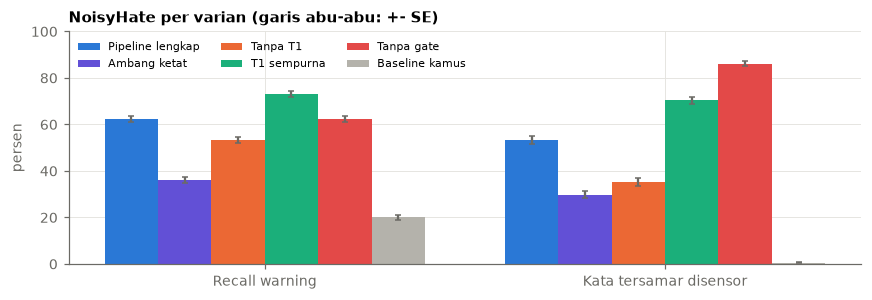

In [13]:
# NoisyHate per Variant
nh_keys = ["warn_recall", "masked_rate_perturbed"]
display(pm_table("noisyhate", VARIANTS, nh_keys))
display(test_table("noisyhate", VARIANTS[1:], nh_keys))

fig, ax = plt.subplots(figsize=(8, 2.8))
x = np.arange(len(nh_keys))
w = 0.8 / len(VARIANTS)
for i, v in enumerate(VARIANTS):
    ax.bar(x + i * w, [pct("noisyhate", v, k) for k in nh_keys], w, color=VARIANT_COLORS[v], label=VARIANT_NAMES[v],
           yerr=[se("noisyhate", v, k) for k in nh_keys], ecolor=MUTED, capsize=2)
ax.set_xticks(x + w * (len(VARIANTS) - 1) / 2, [METRIC_NAMES[k] for k in nh_keys])
ax.set_ylim(0, 100)
ax.set_ylabel("persen")
ax.set_title("NoisyHate per varian (garis abu-abu: +- SE)")
ax.legend(ncol=3, fontsize=7, loc="upper left")
fig.tight_layout()

**Temuan:**

- T1 berpengaruh besar pada kata yang disamarkan. Tanpa T1, pipeline lebih sulit mengenali kalimat tersamar dan lebih sedikit menyensor kata tersamar.
- Dengan normalisasi sempurna, kedua metrik masih naik cukup jauh. Artinya T1 belum memulihkan semua kata tersamar.
- Baseline kamus hampir tidak menyensor kata tersamar, karena bentuk tersamar tidak ada di kamus.
- Tanpa gate, lebih banyak kata tersamar disensor. Dampaknya pada kata yang tidak boleh disensor hanya bisa diukur di CONDA (bagian 6).

Perbandingan varian di atas mengukur pengaruh T1 secara keseluruhan. Tabel berikut memeriksanya per kata: apakah kata tersamar lebih sering disensor jika T1 berhasil mengembalikannya ke bentuk asli.

In [14]:
# Perturbed Words by T1 Recovery
pw = {e["cause"]: e["count"] for e in summary["noisyhate"]["errors"] if e["category"] == "perturbed_word"}
mat = pd.DataFrame({"disensor": [pw["recovered_masked"], pw["not_recovered_masked"]],
                    "tidak disensor": [pw["recovered_unmasked"], pw["not_recovered_unmasked"]]},
                   index=["T1 mengembalikan ke bentuk asli", "T1 tidak mengembalikan"])
mat["persen disensor"] = (mat["disensor"] / mat[["disensor", "tidak disensor"]].sum(axis=1) * 100).round(1)
mat

,disensor,tidak disensor,persen disensor
T1 mengembalikan ke bentuk asli,378,135,73.7
T1 tidak mengembalikan,84,270,23.7


**Temuan:** kata tersamar jauh lebih sering disensor jika T1 berhasil mengembalikannya ke bentuk asli (73.7% dibanding 23.7%). Keberhasilan sensor kata tersamar bergantung pada keberhasilan T1.

## 6. Perbandingan Varian (CONDA bench)

Metrik utama warning dan sensor untuk semua varian, lalu uji beda terhadap pipeline lengkap, lalu rincian untuk melihat kelompok mana yang berubah.

In [15]:
# Main Metrics per Variant
keys = ["warn_precision", "warn_recall", "warn_f1", "censor_precision", "censor_recall", "censor_f1"]
pm_table("conda_bench", VARIANTS, keys)

,Precision warning,Recall warning,F1 warning,Precision sensor,Recall sensor,F1 sensor
Pipeline lengkap,86.8 +- 1.3,83.8 +- 1.4,85.3 +- 1.0,56.1 +- 2.1,84.5 +- 1.7,67.4 +- 1.7
Ambang ketat,93.0 +- 1.1,70.3 +- 1.7,80.1 +- 1.2,59.8 +- 2.2,71.6 +- 2.2,65.2 +- 1.8
Tanpa T1,87.4 +- 1.3,82.7 +- 1.4,85.0 +- 1.0,54.7 +- 2.3,82.2 +- 1.8,65.7 +- 1.8
T1 sempurna,86.4 +- 1.4,83.5 +- 1.4,84.9 +- 1.0,55.1 +- 2.1,84.3 +- 1.7,66.7 +- 1.7
Tanpa gate,86.8 +- 1.3,83.8 +- 1.4,85.3 +- 1.0,19.7 +- 1.0,86.9 +- 1.6,32.1 +- 1.4
Baseline kamus,80.3 +- 2.2,39.1 +- 1.9,52.6 +- 1.9,72.8 +- 2.3,59.1 +- 2.3,65.2 +- 1.9


In [16]:
# Difference Tests
display(test_table("conda_bench", VARIANTS[1:], ["warn_precision", "warn_recall", "warn_f1"]))
display(test_table("conda_bench", VARIANTS[1:], ["censor_precision", "censor_recall", "censor_f1"]))

Precision warning                     Recall warning           \
                         selisih        p signifikan        selisih        p   
Ambang ketat                +6.2  < 0.002         ya          -13.5  < 0.002   
Tanpa T1                    +0.6    0.196      tidak           -1.1    0.012   
T1 sempurna                 -0.4    0.020         ya           -0.3    0.466   
Tanpa gate                  +0.0        -    identik           +0.0        -   
Baseline kamus              -6.5    0.002         ya          -44.7  < 0.002   

                          F1 warning                      
               signifikan    selisih        p signifikan  
Ambang ketat           ya       -5.2  < 0.002         ya  
Tanpa T1               ya       -0.3    0.448      tidak  
T1 sempurna         tidak       -0.4    0.096      tidak  
Tanpa gate        identik       +0.0        -    identik  
Baseline kamus         ya      -32.7  < 0.002         ya

Precision sensor                     Recall sensor           \
                        selisih        p signifikan       selisih        p   
Ambang ketat               +3.7  < 0.002         ya         -12.9  < 0.002   
Tanpa T1                   -1.3    0.212      tidak          -2.4  < 0.002   
T1 sempurna                -0.9    0.150      tidak          -0.2    0.746   
Tanpa gate                -36.4  < 0.002         ya          +2.4  < 0.002   
Baseline kamus            +16.7  < 0.002         ya         -25.4  < 0.002   

                          F1 sensor                      
               signifikan   selisih        p signifikan  
Ambang ketat           ya      -2.2    0.062      tidak  
Tanpa T1               ya      -1.7    0.034         ya  
T1 sempurna         tidak      -0.7    0.118      tidak  
Tanpa gate             ya     -35.3  < 0.002         ya  
Baseline kamus         ya      -2.2    0.292      tidak

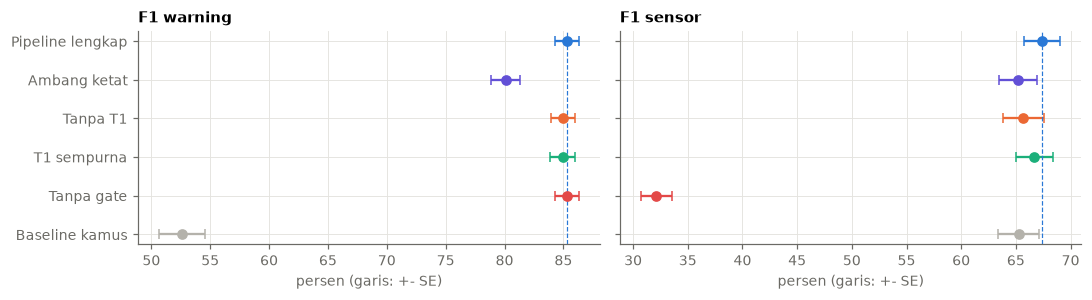

In [17]:
# F1 Chart
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
for ax, m in zip(axes, ["warn_f1", "censor_f1"]):
    for i, v in enumerate(VARIANTS):
        ax.errorbar(pct("conda_bench", v, m), i, xerr=se("conda_bench", v, m), fmt="o", color=VARIANT_COLORS[v],
                    capsize=3)
    ax.axvline(pct("conda_bench", "full", m), color=VARIANT_COLORS["full"], lw=0.8, ls="--")
    ax.set_title(METRIC_NAMES[m])
    ax.set_xlabel("persen (garis: +- SE)")
axes[0].set_yticks(range(len(VARIANTS)), [VARIANT_NAMES[v] for v in VARIANTS])
axes[0].invert_yaxis()
fig.tight_layout()

In [18]:
# Detail per Variant
keys = [f"warned_rate_{k}" for k in INTENTS] + [f"masked_rate_{g}" for g in WORD_GROUPS]
detail_table("conda_bench", VARIANTS, keys)

,Pipeline lengkap,Ambang ketat,Tanpa T1,T1 sempurna,Tanpa gate,Baseline kamus
Baris E diberi warning,88.6,73.4*,87.1*,88.4,88.6,55.0*
Baris I diberi warning,73.8,64.0*,73.3,73.3,73.8,5.8*
Baris A diberi warning,1.0,1.0,0.5,1.0,1.0,1.6
Baris O diberi warning,3.4,1.4*,3.2,3.6,3.4,2.5*
Kata target disensor,84.5,71.6*,82.2*,84.3,86.9*,59.1*
Kata T di baris A/O disensor,30.9,12.4*,28.9,32.0,78.4*,47.4*
Istilah game disensor,3.3,2.7*,3.5,3.3,18.2*,0.8*
Kata lain disensor,2.2,1.7*,2.3,2.4,12.8*,0.4*


**Temuan per varian:**

| Varian | Temuan |
| --- | --- |
| Tanpa gate | Warning tidak berubah. Sensor menangkap sedikit lebih banyak kata target, tetapi jauh lebih banyak kata yang tidak boleh disensor, terutama istilah game dan kata lain. F1 sensor turun sekitar setengahnya. Gate adalah bagian yang membatasi sensor pada baris toksik |
| Tanpa T1 | Recall warning dan recall sensor turun sedikit, tetapi signifikan. Pengaruh T1 di CONDA jauh lebih kecil daripada di NoisyHate |
| T1 sempurna | F1 warning dan F1 sensor tidak berbeda signifikan. Di CONDA, hasil T1 setara dengan normalisasi silver |
| Ambang ketat | Warning lebih tepat, tetapi lebih banyak baris toksik yang lolos, sehingga F1 warning turun. Sensor bergeser ke arah yang sama, dengan F1 tidak berbeda signifikan. Pilihan antara balanced dan strict adalah pilihan antara lebih sedikit salah tuduh dan lebih sedikit toksik yang lolos |
| Baseline kamus | Warning jauh lebih buruk, terutama karena toksik implisit hampir tidak dikenali. Sensor lebih tepat, tetapi lebih banyak kata target yang lolos, dengan F1 tidak berbeda signifikan dari pipeline |

Tabel berikut mengulang uji beda di gold CONDA untuk melihat apakah pola yang sama muncul di data lain.

In [19]:
# Difference Tests Gold CONDA
display(test_table("gold_conda", VARIANTS[1:], ["warn_precision", "warn_recall", "warn_f1"]))
display(test_table("gold_conda", VARIANTS[1:], ["censor_precision", "censor_recall", "censor_f1"]))

Precision warning                   Recall warning           \
                         selisih      p signifikan        selisih        p   
Ambang ketat                +4.0  0.060      tidak          -10.3  < 0.002   
Tanpa T1                    +1.0  0.454      tidak           +0.0    1.000   
T1 sempurna                 -1.3  0.082      tidak           -2.1    0.238   
Tanpa gate                  +0.0      -    identik           +0.0        -   
Baseline kamus              +2.8  0.474      tidak          -36.1  < 0.002   

                          F1 warning                      
               signifikan    selisih        p signifikan  
Ambang ketat           ya       -4.5    0.056      tidak  
Tanpa T1            tidak       +0.4    0.766      tidak  
T1 sempurna         tidak       -1.7    0.082      tidak  
Tanpa gate        identik       +0.0        -    identik  
Baseline kamus         ya      -24.8  < 0.002         ya

Precision sensor                     Recall sensor           \
                        selisih        p signifikan       selisih        p   
Ambang ketat               +3.3    0.280      tidak         -12.5  < 0.002   
Tanpa T1                   -1.5    0.584      tidak          -3.8    0.088   
T1 sempurna                +2.1    0.224      tidak          +0.0        -   
Tanpa gate                -32.6  < 0.002         ya          +2.5    0.332   
Baseline kamus            +23.7  < 0.002         ya         -38.8  < 0.002   

                          F1 sensor                      
               signifikan   selisih        p signifikan  
Ambang ketat           ya      -2.2    0.446      tidak  
Tanpa T1            tidak      -2.3    0.234      tidak  
T1 sempurna       identik      +1.5    0.224      tidak  
Tanpa gate          tidak     -30.0  < 0.002         ya  
Baseline kamus         ya      -7.6    0.176      tidak

**Temuan (gold CONDA):** pengaruh gate, ambang ketat, dan baseline kamus muncul dengan arah yang sama seperti di CONDA bench. Pengaruh T1 tidak signifikan, karena dengan data sekecil ini selisih sebesar di CONDA bench tidak bisa terdeteksi.

## 7. Sumber Kesalahan

Bagian 3 sampai 6 mengukur seberapa sering pipeline salah. Bagian ini menentukan tahap mana yang menyebabkan tiap kesalahan di pipeline lengkap.

Caranya: satu tahap diganti versinya dari bagian 6, lalu diperiksa apakah kesalahan itu hilang.

| Kesalahan | Penyebab | Aturan |
| --- | --- | --- |
| Baris E/I tanpa warning | T1 | Dengan T1 sempurna, T2 memberi warning |
| | T2 | Dengan T1 sempurna, T2 tetap tidak memberi warning |
| Baris A/O diberi warning | T1 | Tanpa T1, T2 tidak memberi warning |
| | T2 | Tanpa T1, T2 tetap memberi warning |
| Kata target tidak disensor | T2 | Baris tanpa warning, dan varian tanpa gate menyensor kata itu |
| | T2+T3 | Baris tanpa warning, dan varian tanpa gate juga tidak menyensor kata itu |
| | T1 | Baris diberi warning, dan dengan T1 sempurna kata itu disensor |
| | T3 | Baris diberi warning, dan dengan T1 sempurna kata itu tetap tidak disensor |
| Kata bukan target disensor | T1 | Dengan T1 sempurna kata itu tidak disensor |
| | T2+T3 | Baris A/O: T2 memberi warning yang salah, lalu T3 memilih kata itu |
| | T3 | Baris E/I dengan warning benar, T3 memilih kata itu |

Kesalahan warning dihitung per baris, kesalahan sensor per kata.

In [20]:
# Error Attribution Table
def error_table(set_name):
    err = pd.DataFrame(summary[set_name]["errors"])
    err = err[err.category.isin(CATEGORY_NAMES)]
    t = err.pivot_table(index="category", columns="cause", values="count", fill_value=0, aggfunc="sum")
    t = t.reindex([c for c in CATEGORY_NAMES if c in t.index])
    t = t.reindex(columns=CAUSES, fill_value=0)
    t["total"] = t.sum(axis=1)
    t.index = [CATEGORY_NAMES[c] for c in t.index]
    return t.rename_axis(columns="penyebab")


bench_err = error_table("conda_bench")
bench_err

penyebab,T1,T2,T3,T2+T3,total
Baris E tanpa warning,1,53,0,0,54
Baris I tanpa warning,0,59,0,0,59
Baris O diberi warning,9,78,0,0,87
Baris A diberi warning,1,1,0,0,2
Kata target tidak disensor,0,11,59,2,72
Kata T di baris A/O disensor,0,0,0,30,30
Istilah game disensor,3,0,56,11,70
Kata lain disensor,7,0,153,48,208


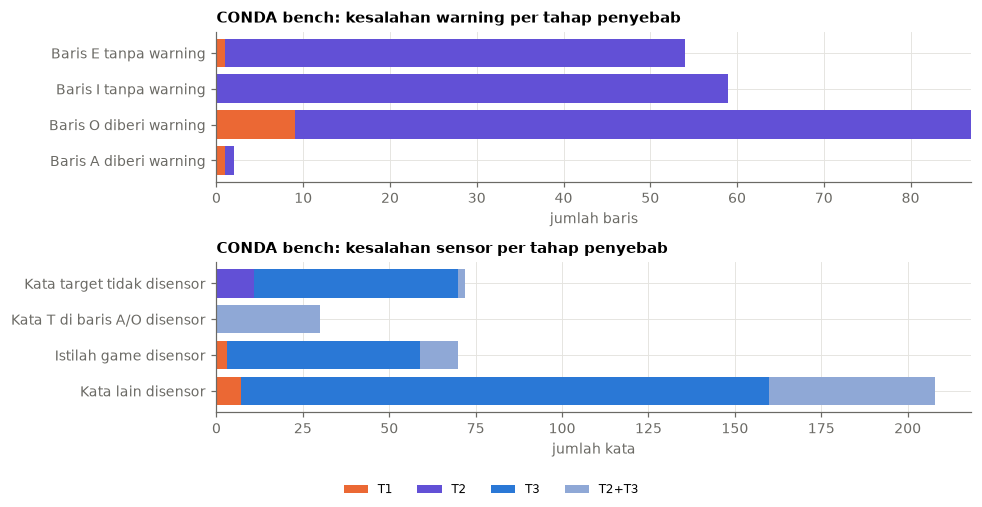

In [21]:
# Error Attribution Chart
plot = bench_err.drop(columns="total")
parts = [(plot.iloc[:4], "kesalahan warning", "jumlah baris"), (plot.iloc[4:], "kesalahan sensor", "jumlah kata")]
fig, axes = plt.subplots(2, 1, figsize=(9, 4.6))
for ax, (part, title, unit) in zip(axes, parts):
    left = np.zeros(len(part))
    for cause in CAUSES:
        ax.barh(part.index, part[cause], left=left, color=CAUSE_COLORS[cause], label=cause)
        left += part[cause].values
    ax.invert_yaxis()
    ax.set_xlabel(unit)
    ax.set_title(f"CONDA bench: {title} per tahap penyebab")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, fontsize=8, loc="lower center")
fig.tight_layout(rect=(0, 0.06, 1, 1))

**Temuan:**

- Hampir semua warning yang salah, baik yang terlewat maupun yang salah diberikan, berasal dari T2.
- Kesalahan sensor sebagian besar berasal dari T3, baik melewatkan kata target maupun memilih kata yang bukan target.
- Sebagian kesalahan sensor berawal dari warning T2 yang salah di baris A/O, termasuk semua kata T di baris A/O yang disensor.
- T1 jarang menjadi penyebab kesalahan di CONDA.

### 7.1 Kata yang Paling Sering Salah

Tabel ini memeriksa apakah kesalahan sensor tersebar di banyak kata atau terkumpul di sedikit kata.

In [22]:
# Top Words per Error Category
words = summary["conda_bench"]["top_words"]
cats = ["missed_target", "masked_t_nontoxic", "masked_game", "masked_other"]
pd.DataFrame({CATEGORY_NAMES[c]: [f"{w} ({n})" for w, n in words[c][:12]] for c in cats})

,Kata target tidak disensor,Kata T di baris A/O disensor,Istilah game disensor,Kata lain disensor
0,noob (30),fuck (9),ez (9),you (14)
1,peru (7),autistic (2),bot (7),trash (13)
2,wtf (6),crap (2),pudge (5),u (9)
3,fuck (5),wtf (1),mid (3),your (6)
4,noobs (4),fucked (1),sf (3),shut (5)
5,fucking (4),fuckj (1),slark (2),up (4)
6,gay (2),noobs (1),donkey (2),die (4)
7,nigga (2),fvck (1),sniper (2),kill (4)
8,shit (2),uck (1),slardar (2),fk (4)
9,abuse (1),whore (1),ezz (2),my (4)


**Temuan:**

- Kata target yang lolos didominasi `noob`, slang umum di chat Dota yang di CONDA berlabel T.
- Istilah game yang disensor adalah slang dan nama hero (`ez`, `bot`, `pudge`). Istilah ini hampir tidak muncul di data latih T3 (SemEval).
- Kata lain yang disensor terdiri dari dua kelompok:
  - Kata kasar yang tidak berlabel T di CONDA (`trash`, `shut up`, `useless`). Benar atau salahnya bergantung pada definisi toksik.
  - Kata ganti yang ikut disensor bersama kata kasar di sebelahnya (`fuck u`).
- Karena kelompok pertama, precision sensor bisa lebih tinggi jika definisi toksik diperluas. Besarnya tidak bisa dihitung tanpa label ulang.

### 7.2 Contoh Kesalahan

Tiga contoh per kesalahan dan penyebab. `kata` adalah kata yang salah untuk kesalahan sensor. `p_toxic` adalah skor T2, warning diberikan jika di atas 0.442.

In [23]:
# Error Examples
ex = pd.read_json(ANA / "conda_bench_examples.jsonl", lines=True)
ex = ex[ex.category.isin(CATEGORY_NAMES)]
ex["kesalahan"] = ex.category.map(CATEGORY_NAMES)
ex = ex.rename(columns={"cause": "penyebab", "raw": "asli", "norm": "hasil T1", "censored": "hasil sensor", "slot": "kata"})
cols = ["kesalahan", "penyebab", "intent", "kata", "asli", "hasil T1", "p_toxic", "hasil sensor"]
ex.groupby(["category", "penyebab"]).head(3)[cols].round(3).fillna("").set_index(["kesalahan", "penyebab"])

intent          kata  \
kesalahan                    penyebab                        
Istilah game disensor        T1            I        sniper   
                             T1            O           ezz   
                             T1            E            ez   
                             T2+T3         O        pounce   
                             T2+T3         O           mid   
                             T2+T3         O         slark   
                             T3            I        deaths   
                             T3            E         pudge   
                             T3            E         pudge   
Kata lain disensor           T1            E       hayshit   
                             T1            E     shhiiittt   
                             T1            E           trx   
                             T2+T3         O         worst   
                             T2+T3         O           dam   
                             T2+T3         O             u   
                             T3            E             u   
                             T3            E        fuaskf   
                             T3            E  mothercukeer   
Kata T di baris A/O disensor T2+T3         O           wtf   
                             T2+T3         O          fuck   
                             T2+T3         O        fucked   
Kata target tidak disensor   T2            E          fuck   
                             T2            E            fu   
                             T2            E          fuck   
                             T2+T3         E         abuse   
                             T2+T3         E        putang   
                             T3            E           gay   
                             T3            E         noobs   
                             T3            E          fuck   
Baris A diberi warning       T1            A                 
                             T2            A                 
Baris O diberi warning       T1            O                 
                             T1            O                 
                             T1            O                 
                             T2            O                 
                             T2            O                 
                             T2            O                 
Baris E tanpa warning        T1            E                 
                             T2            E                 
                             T2            E                 
                             T2            E                 
Baris I tanpa warning        T2            I                 
                             T2            I                 
                             T2            I                 

                                                                                                                            asli  \
kesalahan                    penyebab                                                                                              
Istilah game disensor        T1                                                                              ez setnry by sniper   
                             T1                                                                                              ezz   
                             T1                                                                                         Ez baits   
                             T2+T3                                                                                  worst pounce   
                             T2+T3                                                                             OMG 3 MID U NERDS   
                             T2+T3                                    Good luck If Slark doesnt fuck his pounce Then you're dead   
                             T3                                                                       4/5 deaths BAM BOM BOM BAm 

### 7.3 NoisyHate

Di NoisyHate hanya ada satu jenis kesalahan yang bisa dihitung: kalimat toksik tanpa warning.

In [24]:
# NoisyHate Error Attribution
error_table("noisyhate")

penyebab,T1,T2,T3,T2+T3,total
Baris E tanpa warning,159,347,0,0,506


**Temuan:** sekitar sepertiga kalimat yang lolos akan terdeteksi jika normalisasinya sempurna. Berbeda dengan CONDA, di data tersamar T1 menjadi penyebab kesalahan yang cukup besar.

## 8. Waktu Proses

Moderasi dijalankan sebelum pesan tampil ke pemain lain, sehingga waktu per pesan menentukan apakah pipeline bisa dipakai saat bermain. Diukur pada 300 baris acak CONDA bench, satu baris per panggilan.

- **Median**: separuh pesan selesai lebih cepat dari angka ini.
- **p95**: 95% pesan selesai lebih cepat dari angka ini.
- T3 dijalankan di semua pesan tanpa gate, sehingga waktu T3 adalah batas atas.

In [25]:
# Latency
rows = {}
for path in sorted(RES.glob("latency_*.json")):
    lat = json.loads(path.read_text())
    name = "GPU (" + lat["gpu"] + ")" if "gpu" in lat else "CPU"
    for k, label in [("t1", "T1"), ("t2", "T2"), ("t3", "T3"), ("total", "Total")]:
        rows.setdefault(name, {})[f"{label} median ms"] = lat[k]["p50"]
        rows[name][f"{label} p95 ms"] = lat[k]["p95"]
    rows[name]["Porsi T1 dari median total"] = f"{lat['t1']['p50'] / lat['total']['p50'] * 100:.0f}%"
    rows[name]["Memori GPU puncak MB"] = lat.get("vram_peak_mb", "-")
pd.DataFrame(rows)

,CPU,GPU (NVIDIA GeForce RTX 4050 Laptop GPU)
T1 median ms,229.8,123.8
T1 p95 ms,913.4,397.5
T2 median ms,10.5,7.5
T2 p95 ms,14.5,12.5
T3 median ms,17.9,8.6
T3 p95 ms,25.8,14.2
Total median ms,258.1,141.8
Total p95 ms,951.3,414.2
Porsi T1 dari median total,89%,87%
Memori GPU puncak MB,-,1984


**Temuan:** di GPU, median waktu per pesan sekitar 142 ms. CPU sekitar dua kali lebih lambat. Sebagian besar waktu dipakai T1, karena ByT5 menghasilkan output karakter per karakter. T2 dan T3 hanya butuh beberapa puluh milidetik atau kurang.

## 9. Kesimpulan

| Pertanyaan | Jawaban | Bagian |
| --- | --- | --- |
| Apakah kata yang tidak disensor tetap utuh? | Ya, di semua data uji | 2 |
| Seberapa tepat warning? | Cukup tepat (F1 85.3). Toksik implisit lebih sulit dikenali daripada eksplisit. Warning yang salah jarang | 3 |
| Seberapa tepat sensor? | Sebagian besar kata target disensor, tetapi banyak kata bukan target ikut disensor sehingga precision rendah | 4 |
| Seberapa besar pengaruh T1? | Kecil di CONDA, besar pada kata yang disamarkan. Kata tersamar jauh lebih sering disensor jika T1 berhasil memulihkannya | 5, 6 |
| Seberapa besar pengaruh gate? | Besar. Tanpa gate, F1 sensor turun sekitar setengahnya karena banyak kata di baris tidak toksik ikut disensor | 6 |
| Bagaimana pengaruh ambang ketat? | Lebih sedikit salah tuduh, lebih banyak baris toksik yang lolos | 6 |
| Apakah model lebih baik dari kamus? | Untuk warning dan kata tersamar, ya. Untuk sensor kata kasar umum, F1 keduanya tidak berbeda signifikan | 5, 6 |
| Tahap mana penyebab kesalahan? | Warning: T2. Sensor: T3. T1 jarang menjadi penyebab di CONDA, tetapi berperan di data tersamar | 7 |
| Apakah cukup cepat? | Ya di GPU (median sekitar 142 ms per pesan). T1 adalah tahap paling lambat | 8 |

## 10. Keterbatasan

- Label T CONDA ditentukan oleh bentuk kata. `noob` dihitung toksik dan `trash` tidak, sehingga precision dan recall sensor bergantung pada daftar kata itu. Baseline kamus memakai cara yang mirip dengan cara label dibuat, sehingga perbandingan sensor dengan kamus kemungkinan menguntungkan kamus.
- Kunci sensor mengikuti rancangan "sensor hanya di baris toksik". Kebijakan lain akan memberi angka berbeda. Kelompok kata T di baris A/O ditampilkan terpisah untuk keperluan itu.
- Tiap model dilatih dengan satu seed. SE hanya mencakup variasi data uji.
- T1 sempurna di CONDA bench memakai normalisasi silver. Gold hanya ada di 300 baris gold CONDA.
- Kata tersamar NoisyHate dipakai sebagai pendekatan kata target, padahal sebagian bukan kata kasar.